# Module 3 · Notebook 03 — Modern Local VLMs & Aerial–Tabular Cross-Modal Fusion

Notebook 01 showed that **BLIP base** (2022 captioner) hallucinates everyday phrases on aerial tiles, while Module 2 showed that **tabular building registries hit an $R^2 \approx 0.30$–$0.31$ ceiling** because floor area, year built, and property type omit rooftop hardware, shading, and occupancy. This notebook tests two modern remedies end-to-end on local hardware:

- **Part A · Local VLM Audit (`BLIP base` vs. `SmolVLM-500M-Instruct` vs. `Qwen2.5-VL-3B-Instruct`):** Can compact instruction-tuned vision-language models extract structured JSON on **(A1) 20 cm rooftop PV inspection** (`IGN BD ORTHO`) and **(A2) synthetic EPC & utility bill statements**, without hallucinating panels or mangling numbers?
- **Part B · Aerial + Tabular Multimodal Fusion (`600` Chicago buildings):** We pair Module 2's 2022 building registry with **zoom-19 Esri World Imagery aerial tiles** (`~0.22 m/px` roof footprints), extract frozen aerial embeddings with `SigLIP 2 Base` and `RemoteCLIP ViT-B/32`, and measure strictly leakage-free 5-fold CV lift (`MAE`, `R²`, `stock bias`) across `Ridge`, `LightGBM`, and `TabPFN v2`.

In [1]:
import gc
import io
import json
import math
import os
import re
import sys
import urllib.request
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

ROOT = Path.cwd() if (Path.cwd() / "fm4ues").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

CACHE_DIR = ROOT / "data" / "cache"
AERIAL_DIR = CACHE_DIR / "chicago_aerial_z19"
RESULTS_DIR = ROOT / "benchmarks" / "results"
DOCS_IMG_DIR = ROOT / "docs" / "assets" / "img"
for d in (CACHE_DIR, AERIAL_DIR, RESULTS_DIR, DOCS_IMG_DIR):
    d.mkdir(parents=True, exist_ok=True)

if not os.environ.get("HF_HOME"):
    os.environ["HF_HOME"] = str(CACHE_DIR / "hf")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import transformers
from huggingface_hub import hf_hub_download, snapshot_download
from huggingface_hub.utils import disable_progress_bars, logging as hf_logging
from IPython.display import display
from PIL import Image, ImageDraw, ImageFont
from qwen_vl_utils import process_vision_info
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score, f1_score, r2_score
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion
from transformers import (
    AutoModel,
    AutoModelForImageTextToText,
    AutoProcessor,
    BlipForConditionalGeneration,
    BlipProcessor,
    Qwen2_5_VLForConditionalGeneration,
)

from fm4ues import RunProfiler, inspect_model, mae, portfolio_bias_pct, print_hardware_banner

disable_progress_bars()
hf_logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
transformers.logging.set_verbosity_error()

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print_hardware_banner(DEVICE, CACHE_DIR, ROOT)
profiler = RunProfiler(
    module="module3_multimodal",
    notebook="03_vlm_and_multimodal_fusion",
    device=DEVICE,
    cache_dir=CACHE_DIR,
    results_dir=RESULTS_DIR,
)
profiler.start_run()

W1119 02:16:24.061000 46192 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Python   : 3.11.18 | OS: Windows 10 | RAM: 617 GB
PyTorch  : 2.11.0+cu128
Device   : cuda (Quadro RTX 6000, 25.8 GB VRAM, SM 7.5, TDP 260 W, native fp16, emulated bf16)
Telemetry: NVML GPU power (50 ms) + CodeCarbon offline (system)
Data dir : data\cache


## Part A · Local VLM Inspection & Hallucination Audit

We build two grounded visual test suites with exact verifiable answers:
1. **Task A1 (`20` balanced IGN BD ORTHO 20 cm rooftop tiles):** `10` PV+ roofs (`1–14` annotated solar arrays) and `10` bare roofs from `val`. We audit binary PV detection Accuracy/F1, **false-positive hallucination rate on bare roofs**, structured JSON adherence, and array-count MAE.
2. **Task A2 (`12` synthetic EPC & utility bill statements, `60` grounded fields):** Deterministically rendered PNG statements containing EPC Rating Class (`A–G`), Annual EUI (`kWh/m²/yr`), Monthly Electricity (`kWh`), Peak Demand (`kW`), and Monthly Bill (`EUR`). We measure exact-match field extraction accuracy and **numeric hallucination/parse error rate**.

In [2]:
with profiler.step("1. Prepare VLM rooftop (20) & synthetic EPC bill (12) test suites"):
    ign_dir = Path(snapshot_download("Cyrille37/solar-panels-IGN-bdortho", repo_type="dataset", max_workers=1))
    va_records = []
    for img_p in sorted((ign_dir / "dataset" / "images" / "val").glob("*")):
        lbl_p = ign_dir / "dataset" / "labels" / "val" / f"{img_p.stem}.txt"
        lines = [ln for ln in lbl_p.read_text(encoding="utf-8").splitlines() if ln.strip()] if lbl_p.exists() else []
        va_records.append(
            {
                "id": img_p.stem,
                "pv_present": bool(len(lines) > 0),
                "array_count": len(lines),
                "image": Image.open(img_p).convert("RGB").resize((448, 448), Image.BICUBIC),
            }
        )
    pv_pos = [r for r in va_records if r["pv_present"]][:10]
    pv_neg = [r for r in va_records if not r["pv_present"]][:10]
    a1_items = pv_pos + pv_neg

    # Deterministic EPC & Utility Statement Cards (12 cards x 5 fields = 60 exact ground-truth fields)
    epc_rng = np.random.default_rng(SEED)
    epc_classes = ["A", "B", "C", "D", "E", "F", "G"]
    epc_colors = {
        "A": "#15803d", "B": "#16a34a", "C": "#65a30d",
        "D": "#ca8a04", "E": "#ea580c", "F": "#dc2626", "G": "#991b1b",
    }
    epc_bands = {
        "A": (40, 75), "B": (76, 115), "C": (116, 165),
        "D": (166, 220), "E": (221, 280), "F": (281, 350), "G": (351, 440),
    }

    f_title = ImageFont.load_default(size=22)
    f_lbl = ImageFont.load_default(size=18)
    f_val = ImageFont.load_default(size=22)

    a2_items = []
    for idx in range(12):
        epc = epc_classes[(idx * 2 + 1) % len(epc_classes)]
        lo, hi = epc_bands[epc]
        eui = int(epc_rng.integers(lo, hi + 1))
        m_kwh = int(epc_rng.integers(1400, 9600))
        peak_kw = round(float(epc_rng.uniform(7.5, 48.0)), 1)
        bill_eur = round(m_kwh * float(epc_rng.uniform(0.19, 0.29)) + peak_kw * 4.5, 2)

        im = Image.new("RGB", (680, 400), "#f8fafc")
        dr = ImageDraw.Draw(im)
        dr.rectangle([16, 16, 664, 384], outline="#334155", width=2, fill="#ffffff")
        dr.rectangle([16, 16, 664, 68], fill="#0f172a")
        dr.text((30, 29), f"BUILDING ENERGY & UTILITY STATEMENT #{idx + 1:02d}", fill="#ffffff", font=f_title)
        rows = [
            ("EPC Rating Class:", epc, epc_colors[epc]),
            ("Annual EUI (kWh/m2/yr):", str(eui), "#0f172a"),
            ("Monthly Electricity (kWh):", f"{m_kwh:,}", "#0f172a"),
            ("Peak Demand (kW):", f"{peak_kw:.1f}", "#0f172a"),
            ("Monthly Total Bill (EUR):", f"{bill_eur:.2f}", "#0f172a"),
        ]
        for r_idx, (k_txt, v_txt, col) in enumerate(rows):
            y = 94 + r_idx * 54
            dr.line([(34, y + 40), (646, y + 40)], fill="#e2e8f0", width=1)
            dr.text((38, y), k_txt, fill="#334155", font=f_lbl)
            dr.text((430, y - 2), v_txt, fill=col, font=f_val)

        a2_items.append(
            {
                "id": f"epc_{idx + 1:02d}",
                "epc_class": epc,
                "annual_eui_kwh_m2": eui,
                "monthly_kwh": m_kwh,
                "peak_kw": peak_kw,
                "bill_eur": bill_eur,
                "image": im,
            }
        )

print(f"Prepared Task A1 ({len(a1_items)} roofs: 10 PV+, 10 bare) and Task A2 ({len(a2_items)} EPC cards = {12*5} fields)")

[profile] 1. Prepare VLM rooftop (20) & synthetic EPC bill (12) test suites: 1.1 s | GPU 57 W (61.9 J)
Prepared Task A1 (20 roofs: 10 PV+, 10 bare) and Task A2 (12 EPC cards = 60 fields)


In [3]:
PROMPT_A1 = (
    'Inspect this 20cm aerial rooftop photo. Return ONLY valid JSON with keys '
    '{"pv_present": true/false, "array_count": integer}.'
)
PROMPT_A2 = (
    'Read this energy statement image and return ONLY valid JSON with exact keys '
    '{"epc_class": "A-G", "annual_eui_kwh_m2": int, "monthly_kwh": int, '
    '"peak_kw": float, "bill_eur": float}.'
)


def _extract_json_block(text: str) -> dict | None:
    cleaned = text.strip()
    if "```" in cleaned:
        cleaned = re.sub(r"```(?:json)?", "", cleaned).replace("```", "").strip()
    m = re.search(r"\{.*?\}", cleaned, flags=re.DOTALL)
    if not m:
        return None
    try:
        obj = json.loads(m.group(0))
        return obj if isinstance(obj, dict) else None
    except Exception:
        return None


def _parse_num(val) -> float | None:
    if val is None or isinstance(val, bool):
        return None
    if isinstance(val, (int, float)):
        return float(val)
    s = str(val).replace(",", "")
    m = re.search(r"-?\d+(?:\.\d+)?", s)
    return float(m.group(0)) if m else None


def score_a1_replies(replies: list[str]) -> dict:
    y_true = [int(r["pv_present"]) for r in a1_items]
    y_pred, json_ok, cnt_errs = [], 0, []
    for gt, raw in zip(a1_items, replies):
        obj = _extract_json_block(raw)
        if obj is not None and "pv_present" in obj:
            json_ok += 1
            pred_pv = bool(obj["pv_present"])
            c_val = _parse_num(obj.get("array_count"))
            if c_val is not None and gt["pv_present"]:
                cnt_errs.append(abs(c_val - gt["array_count"]))
        else:
            low = raw.lower()
            pred_pv = any(tok in low for tok in ("true", "solar", "photovoltaic", "panel", "yes")) and not (
                "no solar" in low or "without solar" in low or "false" in low or low.strip().startswith("no")
            )
        y_pred.append(int(pred_pv))

    y_t = np.array(y_true)
    y_p = np.array(y_pred)
    bare_mask = (y_t == 0)
    return {
        "pv_acc_pct": round(100.0 * accuracy_score(y_t, y_p), 1),
        "pv_f1": round(float(f1_score(y_t, y_p, zero_division=0)), 3),
        "bare_roof_fp_pct": round(100.0 * float(y_p[bare_mask].mean()), 1),
        "a1_json_valid_pct": round(100.0 * json_ok / len(a1_items), 1),
        "array_count_mae": round(float(np.mean(cnt_errs)), 2) if cnt_errs else None,
        "preds": y_pred,
    }


def score_a2_replies(replies: list[str]) -> dict:
    json_ok, exact_fields, total_fields = 0, 0, len(a2_items) * 5
    per_field_hits = {k: 0 for k in ("epc_class", "annual_eui_kwh_m2", "monthly_kwh", "peak_kw", "bill_eur")}
    for gt, raw in zip(a2_items, replies):
        obj = _extract_json_block(raw)
        if obj is not None:
            json_ok += 1
        else:
            obj = {}
        epc_p = str(obj.get("epc_class", "")).strip().upper()[:1]
        if epc_p == gt["epc_class"]:
            exact_fields += 1
            per_field_hits["epc_class"] += 1
        for k, tol in [("annual_eui_kwh_m2", 0.5), ("monthly_kwh", 0.5), ("peak_kw", 0.06), ("bill_eur", 0.06)]:
            num = _parse_num(obj.get(k))
            if num is not None and abs(num - float(gt[k])) <= tol:
                exact_fields += 1
                per_field_hits[k] += 1
    return {
        "a2_json_valid_pct": round(100.0 * json_ok / len(a2_items), 1),
        "a2_field_acc_pct": round(100.0 * exact_fields / total_fields, 1),
        "a2_hallucination_or_miss_pct": round(100.0 * (1.0 - exact_fields / total_fields), 1),
        "a2_per_field_pct": {k: round(100.0 * v / len(a2_items), 1) for k, v in per_field_hits.items()},
    }


def eval_vlm_blip() -> dict:
    repo = "Salesforce/blip-image-captioning-base"
    proc = BlipProcessor.from_pretrained(repo)
    mod = BlipForConditionalGeneration.from_pretrained(repo).to(DEVICE).eval()
    card = inspect_model(
        mod, name="BLIP captioning base", family="ViT + causal decoder (2022)",
        modality="Image -> caption", source=repo, license="BSD-3-Clause",
        limits="Captioner only; cannot follow JSON prompts", hf_repo_id=repo,
    )
    profiler.register_model(card)

    # Warmup
    _ = mod.generate(**proc(images=a1_items[0]["image"].resize((384, 384)), return_tensors="pt").to(DEVICE), max_new_tokens=16)
    with profiler.step("VLM A1 · BLIP base (20 roofs)", n_items=len(a1_items), item_unit="image", model_name=card.name):
        a1_replies = []
        with torch.no_grad():
            for r in a1_items:
                inp = proc(images=r["image"].resize((384, 384)), text="an aerial photo of", return_tensors="pt").to(DEVICE)
                out = mod.generate(**inp, max_new_tokens=24)
                a1_replies.append(proc.decode(out[0], skip_special_tokens=True))

    with profiler.step("VLM A2 · BLIP base (12 EPC cards)", n_items=len(a2_items), item_unit="card", model_name=card.name):
        a2_replies = []
        with torch.no_grad():
            for r in a2_items:
                inp = proc(images=r["image"].resize((384, 384)), text="the utility bill statement says", return_tensors="pt").to(DEVICE)
                out = mod.generate(**inp, max_new_tokens=32)
                a2_replies.append(proc.decode(out[0], skip_special_tokens=True))

    s_a1 = next(s for s in reversed(profiler.steps) if s["step"] == "VLM A1 · BLIP base (20 roofs)")
    s_a2 = next(s for s in reversed(profiler.steps) if s["step"] == "VLM A2 · BLIP base (12 EPC cards)")
    m1 = score_a1_replies(a1_replies)
    m2 = score_a2_replies(a2_replies)
    out = {
        "name": card.name, **m1, **m2,
        "a1_sec_per_img": round(s_a1["ms_per_item"] / 1000.0, 2),
        "a1_j_per_img": round(s_a1["mj_per_item"] / 1000.0, 2),
        "a2_j_per_card": round(s_a2["mj_per_item"] / 1000.0, 2),
        "peak_vram_gb": max(s_a1["peak_vram_gb"], s_a2["peak_vram_gb"]),
        "sample_a1": a1_replies[0],
        "sample_a2": a2_replies[0],
    }
    profiler.record_metrics(f"VLM :: {card.name}", {k: v for k, v in out.items() if k not in ("preds", "a2_per_field_pct")})
    del mod, proc
    gc.collect(); torch.cuda.empty_cache()
    return out


def eval_vlm_smolvlm() -> dict:
    repo = "HuggingFaceTB/SmolVLM-500M-Instruct"
    proc = AutoProcessor.from_pretrained(repo)
    mod = AutoModelForImageTextToText.from_pretrained(repo, dtype=torch.float16).to(DEVICE).eval()
    card = inspect_model(
        mod, name="SmolVLM-500M-Instruct", family="Idefics3 VLM (fp16)",
        modality="Image + text -> JSON/text", source=repo, license="Apache-2.0",
        limits="Compact 500M VLM; struggles with strict JSON & dense numbers", hf_repo_id=repo,
    )
    profiler.register_model(card)

    def _run_one(im: Image.Image, prompt_txt: str, max_tok: int = 96) -> str:
        msgs = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": prompt_txt}]}]
        txt = proc.apply_chat_template(msgs, add_generation_prompt=True)
        inp = proc(text=txt, images=[im], return_tensors="pt").to(DEVICE, dtype=torch.float16)
        with torch.no_grad():
            gen = mod.generate(**inp, max_new_tokens=max_tok, do_sample=False)
        return proc.batch_decode(gen[:, inp["input_ids"].shape[1] :], skip_special_tokens=True)[0].strip()

    _ = _run_one(a1_items[0]["image"], PROMPT_A1, max_tok=32)
    with profiler.step("VLM A1 · SmolVLM-500M (20 roofs)", n_items=len(a1_items), item_unit="image", model_name=card.name):
        a1_replies = [_run_one(r["image"], PROMPT_A1, max_tok=64) for r in a1_items]

    with profiler.step("VLM A2 · SmolVLM-500M (12 EPC cards)", n_items=len(a2_items), item_unit="card", model_name=card.name):
        a2_replies = [_run_one(r["image"], PROMPT_A2, max_tok=96) for r in a2_items]

    s_a1 = next(s for s in reversed(profiler.steps) if s["step"] == "VLM A1 · SmolVLM-500M (20 roofs)")
    s_a2 = next(s for s in reversed(profiler.steps) if s["step"] == "VLM A2 · SmolVLM-500M (12 EPC cards)")
    m1 = score_a1_replies(a1_replies)
    m2 = score_a2_replies(a2_replies)
    out = {
        "name": card.name, **m1, **m2,
        "a1_sec_per_img": round(s_a1["ms_per_item"] / 1000.0, 2),
        "a1_j_per_img": round(s_a1["mj_per_item"] / 1000.0, 2),
        "a2_j_per_card": round(s_a2["mj_per_item"] / 1000.0, 2),
        "peak_vram_gb": max(s_a1["peak_vram_gb"], s_a2["peak_vram_gb"]),
        "sample_a1": a1_replies[0],
        "sample_a2": a2_replies[0],
    }
    profiler.record_metrics(f"VLM :: {card.name}", {k: v for k, v in out.items() if k not in ("preds", "a2_per_field_pct")})
    del mod, proc
    gc.collect(); torch.cuda.empty_cache()
    return out


def eval_vlm_qwen() -> dict:
    repo = "Qwen/Qwen2.5-VL-3B-Instruct"
    proc = AutoProcessor.from_pretrained(repo)
    mod = Qwen2_5_VLForConditionalGeneration.from_pretrained(repo, dtype=torch.float16).to(DEVICE).eval()
    card = inspect_model(
        mod, name="Qwen2.5-VL-3B-Instruct", family="Qwen2.5-VL (fp16)",
        modality="Image + text -> structured JSON", source=repo, license="Apache-2.0",
        limits="7.7 GB VRAM in fp16; dynamic native image resolution", hf_repo_id=repo,
    )
    profiler.register_model(card)

    def _run_one(im: Image.Image, prompt_txt: str, max_tok: int = 96) -> str:
        msgs = [{"role": "user", "content": [{"type": "image", "image": im}, {"type": "text", "text": prompt_txt}]}]
        txt = proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        img_inps, vid_inps = process_vision_info(msgs)
        inp = proc(text=[txt], images=img_inps, videos=vid_inps, padding=True, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            gen = mod.generate(**inp, max_new_tokens=max_tok, do_sample=False)
        return proc.batch_decode(gen[:, inp["input_ids"].shape[1] :], skip_special_tokens=True)[0].strip()

    _ = _run_one(a1_items[0]["image"], PROMPT_A1, max_tok=32)
    with profiler.step("VLM A1 · Qwen2.5-VL-3B (20 roofs)", n_items=len(a1_items), item_unit="image", model_name=card.name):
        a1_replies = [_run_one(r["image"], PROMPT_A1, max_tok=64) for r in a1_items]

    with profiler.step("VLM A2 · Qwen2.5-VL-3B (12 EPC cards)", n_items=len(a2_items), item_unit="card", model_name=card.name):
        a2_replies = [_run_one(r["image"], PROMPT_A2, max_tok=96) for r in a2_items]

    s_a1 = next(s for s in reversed(profiler.steps) if s["step"] == "VLM A1 · Qwen2.5-VL-3B (20 roofs)")
    s_a2 = next(s for s in reversed(profiler.steps) if s["step"] == "VLM A2 · Qwen2.5-VL-3B (12 EPC cards)")
    m1 = score_a1_replies(a1_replies)
    m2 = score_a2_replies(a2_replies)
    out = {
        "name": card.name, **m1, **m2,
        "a1_sec_per_img": round(s_a1["ms_per_item"] / 1000.0, 2),
        "a1_j_per_img": round(s_a1["mj_per_item"] / 1000.0, 2),
        "a2_j_per_card": round(s_a2["mj_per_item"] / 1000.0, 2),
        "peak_vram_gb": max(s_a1["peak_vram_gb"], s_a2["peak_vram_gb"]),
        "sample_a1": a1_replies[0],
        "sample_a2": a2_replies[0],
    }
    profiler.record_metrics(f"VLM :: {card.name}", {k: v for k, v in out.items() if k not in ("preds", "a2_per_field_pct")})
    del mod, proc
    gc.collect(); torch.cuda.empty_cache()
    return out


vlm_results = [eval_vlm_blip(), eval_vlm_smolvlm(), eval_vlm_qwen()]

print("Table 1 · Local VLM Audit on 20 cm Rooftop PV (A1) & EPC Bill OCR (A2):")
vlm_df = pd.DataFrame(
    [
        {
            "Model": r["name"],
            "PV Acc (%)": r["pv_acc_pct"],
            "PV F1": r["pv_f1"],
            "Bare-Roof FP (%)": r["bare_roof_fp_pct"],
            "A1 JSON Valid (%)": r["a1_json_valid_pct"],
            "EPC Field Acc (%)": r["a2_field_acc_pct"],
            "EPC Miss/Halluc (%)": r["a2_hallucination_or_miss_pct"],
            "s / roof": r["a1_sec_per_img"],
            "J / card": r["a2_j_per_card"],
            "Peak VRAM (GB)": r["peak_vram_gb"],
        }
        for r in vlm_results
    ]
).set_index("Model")
display(vlm_df)

c0 = a2_items[0]
print(
    f"\nSample outputs on Roof #1 (true PV+=True, {a1_items[0]['array_count']} arr) & "
    f"Statement #01 (EPC={c0['epc_class']}, EUI={c0['annual_eui_kwh_m2']}, "
    f"{c0['monthly_kwh']} kWh, {c0['peak_kw']} kW, {c0['bill_eur']:.2f} EUR):"
)
for r in vlm_results:
    print(f"  [{r['name']}] A1 -> {r['sample_a1']!r}")
    print(f"  [{r['name']}] A2 -> {r['sample_a2']!r}")

[profile] VLM A1 · BLIP base (20 roofs): 4.3 s | VRAM 0.97 GB | GPU 67 W (286.5 J) | 213.13 ms/image


[profile] VLM A2 · BLIP base (12 EPC cards): 2.6 s | VRAM 0.97 GB | GPU 55 W (146.7 J) | 220.77 ms/card


[profile] VLM A1 · SmolVLM-500M (20 roofs): 40.9 s | VRAM 1.50 GB | GPU 97 W (3977.9 J) | 2045.67 ms/image


[profile] VLM A2 · SmolVLM-500M (12 EPC cards): 54.3 s | VRAM 1.39 GB | GPU 64 W (3477.4 J) | 4528.50 ms/card


[profile] VLM A1 · Qwen2.5-VL-3B (20 roofs): 30.1 s | VRAM 7.69 GB | GPU 128 W (3856.2 J) | 1504.17 ms/image


[profile] VLM A2 · Qwen2.5-VL-3B (12 EPC cards): 53.8 s | VRAM 7.72 GB | GPU 106 W (5690.7 J) | 4481.90 ms/card


Table 1 · Local VLM Audit on 20 cm Rooftop PV (A1) & EPC Bill OCR (A2):


,PV Acc (%),PV F1,Bare-Roof FP (%),A1 JSON Valid (%),EPC Field Acc (%),EPC Miss/Halluc (%),s / roof,J / card,Peak VRAM (GB)
Model,,,,,,,,,
BLIP captioning base,70.0,0.571,0.0,0.0,0.0,100.0,0.21,12.22,0.966
SmolVLM-500M-Instruct,55.0,0.690,90.0,80.0,76.7,23.3,2.05,289.78,1.496
Qwen2.5-VL-3B-Instruct,80.0,0.750,0.0,100.0,100.0,0.0,1.50,474.22,7.720



Sample outputs on Roof #1 (true PV+=True, 1 arr) & Statement #01 (EPC=B, EUI=79, 7746 kWh, 25.3 kW, 2250.66 EUR):
  [BLIP captioning base] A1 -> 'an aerial photo of the new building at the site of the former nuclear facility'
  [BLIP captioning base] A2 -> 'the utility bill statement says it is a good investment option'
  [SmolVLM-500M-Instruct] A1 -> '{\n    "array_count": 1,\n    "pv_present": true\n}'
  [SmolVLM-500M-Instruct] A2 -> '{\n    "epc_class": "A-G",\n    "annual_eui_kwh_m2": 79,\n    "monthly_kwh": 7,746,\n    "peak_kw": 25.3,\n    "bill_eur": 2250.66\n}'
  [Qwen2.5-VL-3B-Instruct] A1 -> '```json\n{\n  "pv_present": false,\n  "array_count": 0\n}\n```'
  [Qwen2.5-VL-3B-Instruct] A2 -> '```json\n{\n  "epc_class": "B",\n  "annual_eui_kwh_m2": 79,\n  "monthly_kwh": 7746,\n  "peak_kw": 25.3,\n  "bill_eur": 2250.66\n}\n```'


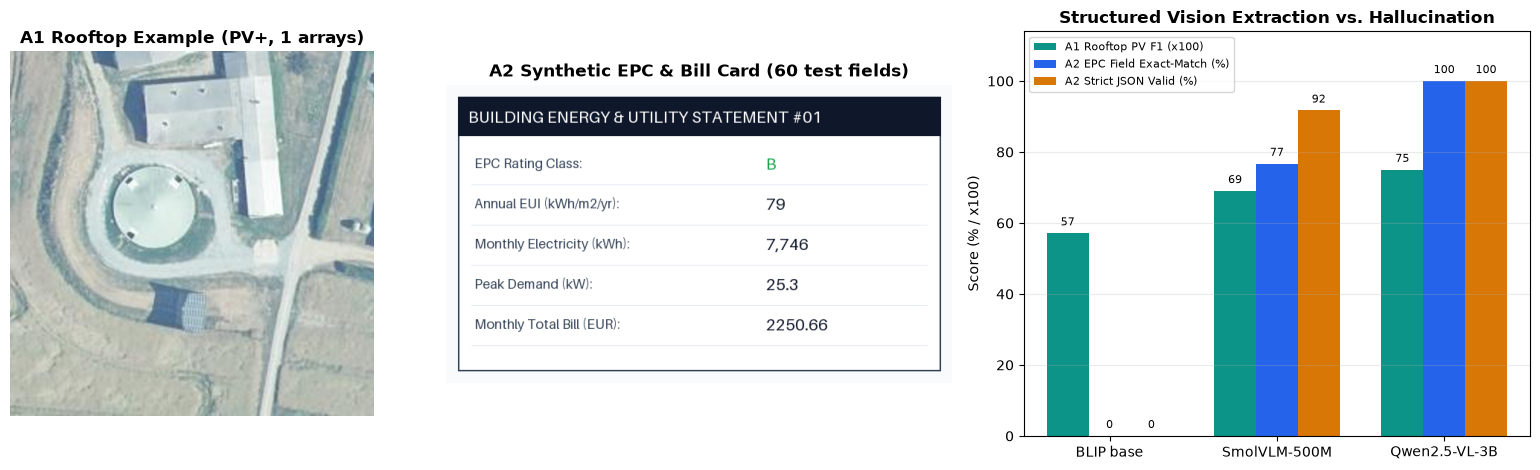

In [4]:
fig_v, (ax_ex1, ax_ex2, ax_bar) = plt.subplots(1, 3, figsize=(15.5, 4.8), gridspec_kw={"width_ratios": [0.9, 1.25, 1.25]})

ax_ex1.imshow(a1_items[0]["image"])
ax_ex1.axis("off")
ax_ex1.set_title(f"A1 Rooftop Example (PV+, {a1_items[0]['array_count']} arrays)", fontweight="bold")

ax_ex2.imshow(a2_items[0]["image"])
ax_ex2.axis("off")
ax_ex2.set_title("A2 Synthetic EPC & Bill Card (60 test fields)", fontweight="bold")

x_v = np.arange(len(vlm_results))
w_v = 0.25
m_names = ["BLIP base", "SmolVLM-500M", "Qwen2.5-VL-3B"]
b1 = ax_bar.bar(x_v - w_v, [r["pv_f1"] * 100.0 for r in vlm_results], width=w_v, color="#0d9488", label="A1 Rooftop PV F1 (x100)")
b2 = ax_bar.bar(x_v, [r["a2_field_acc_pct"] for r in vlm_results], width=w_v, color="#2563eb", label="A2 EPC Field Exact-Match (%)")
b3 = ax_bar.bar(x_v + w_v, [r["a2_json_valid_pct"] for r in vlm_results], width=w_v, color="#d97706", label="A2 Strict JSON Valid (%)")
for bar in list(b1) + list(b2) + list(b3):
    h = bar.get_height()
    ax_bar.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f"{h:.0f}", ha="center", va="bottom", fontsize=7.8)
ax_bar.set_xticks(x_v)
ax_bar.set_xticklabels(m_names)
ax_bar.set_ylim(0, 114)
ax_bar.set_ylabel("Score (% / x100)")
ax_bar.set_title("Structured Vision Extraction vs. Hallucination", fontweight="bold")
ax_bar.grid(axis="y", alpha=0.25)
ax_bar.legend(fontsize=8, loc="upper left")

plt.tight_layout()
fig_v.savefig(DOCS_IMG_DIR / "m3_vlm_audit.png", dpi=180, bbox_inches="tight")
plt.show()

## Part B · Cross-Modal Aerial + Tabular Fusion (`Chicago Buildings 2022`)

Can overhead imagery of a building's roof, lot geometry, and surrounding neighborhood block explain the energy variance missed by municipal benchmarking tables? We test this directly on **600 cleaned Chicago buildings** from Module 2 (`data/cache/chicago_benchmarking_2022.csv`):

1. Fetch & cache zoom-19 Esri World Imagery `256 × 256` tiles (`~0.22 m/px`) for each `(latitude, longitude)` into `data/cache/chicago_aerial_z19/`.
2. Extract frozen image embeddings via **SigLIP 2 Base** and **RemoteCLIP ViT-B/32**.
3. Run strictly **leakage-free 5-fold CV** (`StandardScaler` + `PCA(n_components=16)` fit inside each training fold) across `Ridge`, `LightGBM`, and `TabPFN v2` comparing **Tabular only**, **Aerial image only**, and **Cross-modal fusion**.

In [5]:
CHI_API_URL = "https://data.cityofchicago.org/resource/xq83-jr8c.csv"
chi_csv = CACHE_DIR / "chicago_benchmarking_2022.csv"
if not chi_csv.exists():
    import requests
    resp = requests.get(CHI_API_URL, params={"$where": "data_year=2022", "$limit": 50000}, timeout=120)
    resp.raise_for_status()
    chi_csv.write_text(resp.text, encoding="utf-8")

raw_chi = pd.read_csv(chi_csv)
df_chi = raw_chi[raw_chi["reporting_status"].str.contains("Submitted", na=False)].copy()
COLS_KEEP = [
    "id", "primary_property_type", "gross_floor_area_buildings_sq_ft",
    "year_built", "of_buildings", "latitude", "longitude", "community_area",
    "site_eui_kbtu_sq_ft",
]
df_chi = df_chi[COLS_KEEP].dropna()
df_chi = df_chi[(df_chi["site_eui_kbtu_sq_ft"] > 5) & (df_chi["site_eui_kbtu_sq_ft"] < 500)].reset_index(drop=True)
df_chi["community_area"] = df_chi["community_area"].astype(str).str.strip().str.upper()
df_chi["log_floor_area"] = np.log10(df_chi["gross_floor_area_buildings_sq_ft"])

# Deterministic stratified sample of 600 buildings across common property types
top_types = df_chi["primary_property_type"].value_counts()
rare_label = "Other"
strata = df_chi["primary_property_type"].where(df_chi["primary_property_type"].isin(top_types[top_types >= 25].index), rare_label)
df_chi["_stratum"] = strata
sample_parts = []
frac = 600.0 / len(df_chi)
for st, grp in df_chi.groupby("_stratum", sort=True):
    n_take = max(5, int(round(len(grp) * frac)))
    sample_parts.append(grp.sample(n=min(len(grp), n_take), random_state=SEED))
df_sub = pd.concat(sample_parts).sample(n=600, random_state=SEED).reset_index(drop=True)


def latlon_to_tile(lat: float, lon: float, z: int = 19) -> tuple[int, int]:
    lr = math.radians(lat)
    n = 2**z
    return int((lon + 180.0) / 360.0 * n), int((1.0 - math.asinh(math.tan(lr)) / math.pi) / 2.0 * n)


def fetch_esri_tile(task: tuple[int, int, int]) -> tuple[int, int, Path]:
    z, tx, ty = task
    out_p = AERIAL_DIR / f"{z}_{tx}_{ty}.jpg"
    if out_p.exists() and out_p.stat().st_size > 1500:
        return tx, ty, out_p
    url = f"https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{ty}/{tx}"
    for _ in range(3):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "FM4UES-playground/1.0"})
            with urllib.request.urlopen(req, timeout=10) as r:
                data = r.read()
                if len(data) > 500:
                    out_p.write_bytes(data)
                    return tx, ty, out_p
        except Exception:
            continue
    raise RuntimeError(f"Failed fetching tile {(z, tx, ty)}")


tile_keys = [latlon_to_tile(float(r.latitude), float(r.longitude), 19) for r in df_sub.itertuples()]
unique_tasks = sorted({(19, tx, ty) for tx, ty in tile_keys})

with profiler.step("2. Fetch/load zoom-19 Esri Chicago aerial tiles (600 bldgs)", n_items=len(unique_tasks), item_unit="tile"):
    with ThreadPoolExecutor(max_workers=6) as ex:
        fetched = list(ex.map(fetch_esri_tile, unique_tasks))

tile_path_map = {(tx, ty): p for tx, ty, p in fetched}
aerial_imgs = [Image.open(tile_path_map[k]).convert("RGB") for k in tile_keys]
print(f"Loaded {len(aerial_imgs)} aerial footprints ({len(unique_tasks)} unique zoom-19 tiles, cached).")

[profile] 2. Fetch/load zoom-19 Esri Chicago aerial tiles (600 bldgs): 0.1 s | VRAM 0.01 GB | GPU 48 W (4.7 J) | 0.16 ms/tile


Loaded 600 aerial footprints (581 unique zoom-19 tiles, cached).


In [6]:
# Encode 600 aerial roofs cleanly with SigLIP 2 Base and RemoteCLIP ViT-B/32
with profiler.step("3a. Extract SigLIP 2 aerial embeddings (600 bldgs)", n_items=len(aerial_imgs), item_unit="image", model_name="SigLIP 2 Base"):
    sig_p = AutoProcessor.from_pretrained("google/siglip2-base-patch16-224")
    sig_m = AutoModel.from_pretrained("google/siglip2-base-patch16-224").to(DEVICE).eval()
    profiler.register_model(inspect_model(sig_m, name="SigLIP 2 Base", family="Sigmoid ViT-B/16", modality="Image -> 768-D", source="google/siglip2-base-patch16-224", license="Apache-2.0", hf_repo_id="google/siglip2-base-patch16-224"))
    sig_chunks = []
    with torch.no_grad():
        for i in range(0, len(aerial_imgs), 64):
            inp = sig_p(images=aerial_imgs[i : i + 64], return_tensors="pt").to(DEVICE)
            f = sig_m.get_image_features(**inp)
            f = f if isinstance(f, torch.Tensor) else f.pooler_output
            sig_chunks.append(torch.nn.functional.normalize(f.float(), dim=-1).cpu().numpy())
    X_siglip = np.vstack(sig_chunks)
    del sig_m, sig_p
    gc.collect(); torch.cuda.empty_cache()

with profiler.step("3b. Extract RemoteCLIP aerial embeddings (600 bldgs)", n_items=len(aerial_imgs), item_unit="image", model_name="RemoteCLIP ViT-B/32"):
    rc_ckpt = hf_hub_download("chendelong/RemoteCLIP", "RemoteCLIP-ViT-B-32.pt")
    rc_m, _, rc_pre = open_clip.create_model_and_transforms("ViT-B-32")
    rc_m.load_state_dict(torch.load(rc_ckpt, map_location="cpu", weights_only=True), strict=True)
    rc_m = rc_m.to(DEVICE).eval()
    profiler.register_model(inspect_model(rc_m, name="RemoteCLIP ViT-B/32", family="RS-adapted CLIP ViT-B/32", modality="Image -> 512-D", source="chendelong/RemoteCLIP", license="Unspecified on HF card", disk_path=rc_ckpt))
    rc_chunks = []
    with torch.no_grad():
        for i in range(0, len(aerial_imgs), 64):
            ten = torch.stack([rc_pre(im) for im in aerial_imgs[i : i + 64]]).to(DEVICE)
            rc_chunks.append(torch.nn.functional.normalize(rc_m.encode_image(ten).float(), dim=-1).cpu().numpy())
    X_rclip = np.vstack(rc_chunks)
    del rc_m
    gc.collect(); torch.cuda.empty_cache()

# Build Module 2 tabular feature matrix
TOP_T = sorted(df_sub["primary_property_type"].value_counts()[lambda s: s >= 12].index)
TOP_A = sorted(df_sub["community_area"].value_counts().head(15).index)
btype = df_sub["primary_property_type"].where(df_sub["primary_property_type"].isin(TOP_T), "Other")
barea = df_sub["community_area"].where(df_sub["community_area"].isin(TOP_A), "OTHER_AREA")
X_tab_df = pd.concat(
    [
        df_sub[["log_floor_area", "year_built", "of_buildings", "latitude", "longitude"]].reset_index(drop=True),
        pd.get_dummies(btype, prefix="type", dtype=float).reset_index(drop=True),
        pd.get_dummies(barea, prefix="area", dtype=float).reset_index(drop=True),
    ],
    axis=1,
)
X_tab = X_tab_df.to_numpy(dtype=np.float32)
y_eui = df_sub["site_eui_kbtu_sq_ft"].to_numpy(dtype=np.float32)
areas_sqft = df_sub["gross_floor_area_buildings_sq_ft"].to_numpy(dtype=np.float64)

print(f"Feature matrix -> Tabular: {X_tab.shape}, SigLIP 2: {X_siglip.shape}, RemoteCLIP: {X_rclip.shape}")


def eval_5fold_fusion(modal_tag: str, img_emb: np.ndarray | None, use_tab: bool = True, pca_dim: int = 16) -> dict:
    kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
    preds = {k: np.zeros_like(y_eui, dtype=float) for k in ("Ridge", "LightGBM", "TabPFN v2")}

    tabpfn_model = TabPFNRegressor.create_default_for_version(ModelVersion.V2, device=DEVICE, random_state=SEED)

    with profiler.step(f"4. 5-fold CV · {modal_tag}", n_items=len(y_eui), item_unit="bldg"):
        for tr_i, va_i in kf.split(X_tab):
            parts_tr, parts_va = [], []
            if use_tab:
                sc_t = StandardScaler().fit(X_tab[tr_i])
                parts_tr.append(sc_t.transform(X_tab[tr_i]))
                parts_va.append(sc_t.transform(X_tab[va_i]))
            if img_emb is not None:
                sc_i = StandardScaler().fit(img_emb[tr_i])
                pca = PCA(n_components=pca_dim, random_state=SEED).fit(sc_i.transform(img_emb[tr_i]))
                parts_tr.append(pca.transform(sc_i.transform(img_emb[tr_i])))
                parts_va.append(pca.transform(sc_i.transform(img_emb[va_i])))
            Xtr = np.hstack(parts_tr).astype(np.float32)
            Xva = np.hstack(parts_va).astype(np.float32)

            m_ridge = Ridge(alpha=10.0).fit(Xtr, y_eui[tr_i])
            preds["Ridge"][va_i] = m_ridge.predict(Xva)

            m_lgb = lgb.LGBMRegressor(
                n_estimators=180, learning_rate=0.05, num_leaves=15,
                subsample_for_bin=400, min_child_samples=15, random_state=SEED, verbose=-1,
            ).fit(Xtr, y_eui[tr_i])
            preds["LightGBM"][va_i] = m_lgb.predict(Xva)

            tabpfn_model.fit(Xtr, y_eui[tr_i])
            preds["TabPFN v2"][va_i] = tabpfn_model.predict(Xva)

    if modal_tag == "Tabular only":
        profiler.register_model(inspect_model(tabpfn_model, name="TabPFN v2 (fusion CV)", family="In-context Transformer", modality="Tabular / Fused", source="Prior-Labs/TabPFN-v2-reg", license="Prior Labs (Apache 2.0)", disk_mb=44.4))

    del tabpfn_model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

    out = {}
    for m_name, p_arr in preds.items():
        m_val = round(mae(y_eui, p_arr), 2)
        r2_val = round(float(r2_score(y_eui, p_arr)), 3)
        bias_val = round(portfolio_bias_pct(y_eui, p_arr, weights=areas_sqft), 2)
        out[m_name] = {"mae": m_val, "r2": r2_val, "stock_bias_pct": bias_val}
        profiler.record_metrics(
            f"Fusion :: {modal_tag} / {m_name}",
            {"modality": modal_tag, "regressor": m_name, "mae_kbtu_sqft": m_val, "r2": r2_val, "stock_bias_pct": bias_val},
        )
    return out


fusion_results = {
    "Tabular only": eval_5fold_fusion("Tabular only", None, use_tab=True),
    "Aerial only (SigLIP 2)": eval_5fold_fusion("Aerial only (SigLIP 2)", X_siglip, use_tab=False),
    "Aerial only (RemoteCLIP)": eval_5fold_fusion("Aerial only (RemoteCLIP)", X_rclip, use_tab=False),
    "Fused (Tab + SigLIP 2)": eval_5fold_fusion("Fused (Tab + SigLIP 2)", X_siglip, use_tab=True),
    "Fused (Tab + RemoteCLIP)": eval_5fold_fusion("Fused (Tab + RemoteCLIP)", X_rclip, use_tab=True),
}

rows_f = []
for mod_name, d_mod in fusion_results.items():
    for reg_name, mvals in d_mod.items():
        rows_f.append(
            {
                "Modality": mod_name,
                "Regressor": reg_name,
                "MAE (kBtu/ft²)": mvals["mae"],
                "R²": mvals["r2"],
                "Stock Bias (%)": f"{mvals['stock_bias_pct']:+.2f}%",
            }
        )
print("Table 2 · 5-Fold Leakage-Free CV on 600 Chicago Buildings (Tabular vs. Aerial vs. Fusion):")
display(pd.DataFrame(rows_f))

[profile] 3a. Extract SigLIP 2 aerial embeddings (600 bldgs): 10.7 s | VRAM 2.01 GB | GPU 89 W (949.0 J) | 17.86 ms/image


No pretrained weights loaded for model 'ViT-B-32'. Model initialized randomly.


[profile] 3b. Extract RemoteCLIP aerial embeddings (600 bldgs): 4.9 s | VRAM 0.79 GB | GPU 78 W (378.6 J) | 8.09 ms/image
Feature matrix -> Tabular: (600, 28), SigLIP 2: (600, 768), RemoteCLIP: (600, 512)


[profile] 4. 5-fold CV · Tabular only: 5.5 s | VRAM 0.15 GB | GPU 69 W (379.5 J) | 9.10 ms/bldg


[profile] 4. 5-fold CV · Aerial only (SigLIP 2): 4.5 s | VRAM 0.15 GB | GPU 77 W (345.1 J) | 7.50 ms/bldg


[profile] 4. 5-fold CV · Aerial only (RemoteCLIP): 4.6 s | VRAM 0.15 GB | GPU 99 W (460.5 J) | 7.71 ms/bldg


[profile] 4. 5-fold CV · Fused (Tab + SigLIP 2): 6.8 s | VRAM 0.20 GB | GPU 102 W (694.2 J) | 11.30 ms/bldg


[profile] 4. 5-fold CV · Fused (Tab + RemoteCLIP): 6.6 s | VRAM 0.20 GB | GPU 117 W (774.8 J) | 10.98 ms/bldg


Table 2 · 5-Fold Leakage-Free CV on 600 Chicago Buildings (Tabular vs. Aerial vs. Fusion):


,Modality,Regressor,MAE (kBtu/ft²),R²,Stock Bias (%)
0,Tabular only,Ridge,28.86,0.051,+1.65%
1,Tabular only,LightGBM,29.83,0.081,-0.30%
2,Tabular only,TabPFN v2,26.96,0.182,+4.01%
3,Aerial only (SigLIP 2),Ridge,29.88,0.017,+6.21%
4,Aerial only (SigLIP 2),LightGBM,32.52,-0.073,+9.40%
5,Aerial only (SigLIP 2),TabPFN v2,29.41,0.012,+4.12%
6,Aerial only (RemoteCLIP),Ridge,30.44,0.019,+5.98%
7,Aerial only (RemoteCLIP),LightGBM,33.02,-0.094,+7.31%
8,Aerial only (RemoteCLIP),TabPFN v2,29.40,0.019,+3.91%
9,Fused (Tab + SigLIP 2),Ridge,28.85,0.094,+3.05%


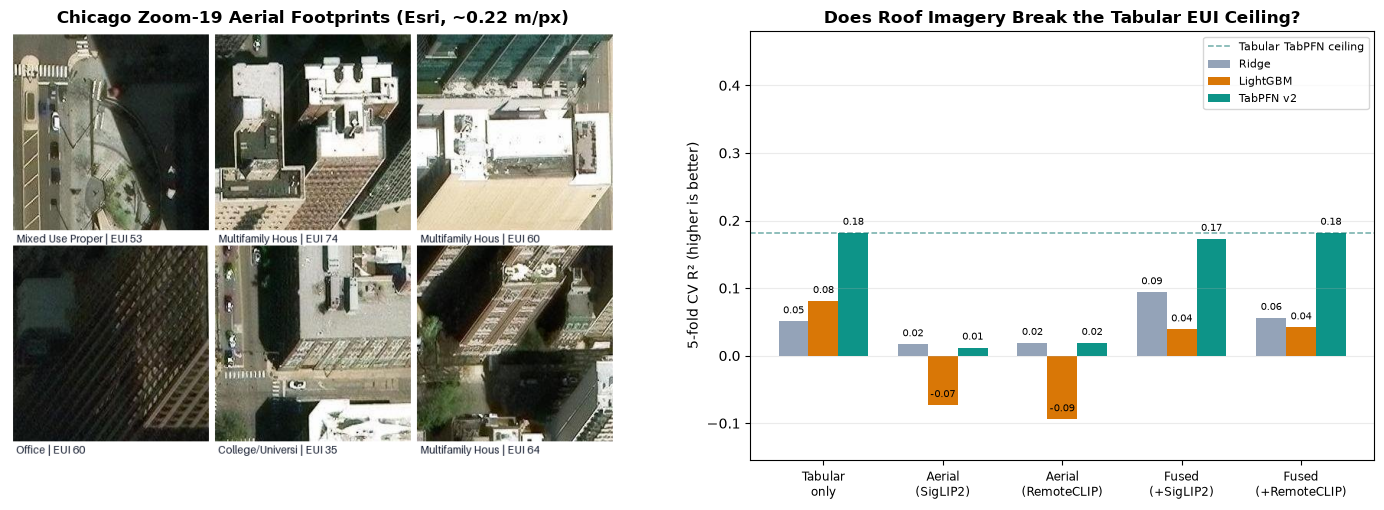

In [7]:
fig_f, (ax_tiles, ax_bars) = plt.subplots(1, 2, figsize=(14.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1.0]})

# Left: composite grid of 6 real zoom-19 Chicago building tiles
ax_tiles.axis("off")
grid_canvas = Image.new("RGB", (3 * 256 + 24, 2 * 256 + 48), "#ffffff")
dr_g = ImageDraw.Draw(grid_canvas)
f_tile = ImageFont.load_default(size=14)
sample_idxs = np.linspace(0, len(df_sub) - 1, 6, dtype=int)
for j, b_idx in enumerate(sample_idxs):
    r_i, c_i = divmod(j, 3)
    x0 = c_i * 264 + 4
    y0 = r_i * 276 + 4
    grid_canvas.paste(aerial_imgs[b_idx], (x0, y0))
    row = df_sub.iloc[b_idx]
    lbl = f"{row['primary_property_type'][:16]} | EUI {row['site_eui_kbtu_sq_ft']:.0f}"
    dr_g.text((x0 + 4, y0 + 258), lbl, fill="#0f172a", font=f_tile)
ax_tiles.imshow(grid_canvas)
ax_tiles.set_title("Chicago Zoom-19 Aerial Footprints (Esri, ~0.22 m/px)", fontweight="bold")

# Right: R^2 grouped comparison across modalities
modal_labels = ["Tabular\nonly", "Aerial\n(SigLIP2)", "Aerial\n(RemoteCLIP)", "Fused\n(+SigLIP2)", "Fused\n(+RemoteCLIP)"]
modal_keys = list(fusion_results.keys())
xm = np.arange(len(modal_keys))
wm = 0.25
for idx_r, (reg, col) in enumerate([("Ridge", "#94a3b8"), ("LightGBM", "#d97706"), ("TabPFN v2", "#0d9488")]):
    vals = [fusion_results[mk][reg]["r2"] for mk in modal_keys]
    bs = ax_bars.bar(xm + (idx_r - 1) * wm, vals, width=wm, color=col, label=reg)
    for b in bs:
        h = b.get_height()
        ax_bars.text(b.get_x() + b.get_width() / 2, h + 0.008, f"{h:.2f}", ha="center", va="bottom", fontsize=7.5)

ax_bars.axhline(fusion_results["Tabular only"]["TabPFN v2"]["r2"], linestyle="--", color="#0f766e", alpha=0.6, lw=1.1, label="Tabular TabPFN ceiling")
ax_bars.set_xticks(xm)
ax_bars.set_xticklabels(modal_labels, fontsize=8.5)
all_r2 = [fusion_results[mk][rg]["r2"] for mk in modal_keys for rg in ("Ridge", "LightGBM", "TabPFN v2")]
ax_bars.set_ylim(min(0.0, min(all_r2) - 0.06), max(0.48, max(all_r2) + 0.08))
ax_bars.set_ylabel("5-fold CV R² (higher is better)")
ax_bars.set_title("Does Roof Imagery Break the Tabular EUI Ceiling?", fontweight="bold")
ax_bars.grid(axis="y", alpha=0.25)
ax_bars.legend(fontsize=8, loc="upper right")

plt.tight_layout()
fig_f.savefig(DOCS_IMG_DIR / "m3_multimodal_fusion.png", dpi=180, bbox_inches="tight")
plt.show()

In [8]:
profiler.stop_run()
csv_path, json_path = profiler.save()

print("Model Cards:")
display(profiler.model_card_table())

print("\nPer-Step Latency, VRAM, Power & GPU Energy:")
display(profiler.summary_table())

print("\nWhole-Notebook Energy & Grid CO2e Comparison:")
display(profiler.energy_summary_table())

print(f"Exported benchmarks/results/{json_path.name}")

Model Cards:


,Params (M),Precision,Disk (MB),Peak VRAM (GB),Min Hardware,Licence,Limits
Model,,,,,,,
BLIP captioning base,223.97,float32,1980.5,0.966,GPU <= 4 GB,BSD-3-Clause,Captioner only; cannot follow JSON prompts
SmolVLM-500M-Instruct,507.48,float16,1019.9,1.496,GPU <= 4 GB,Apache-2.0,Compact 500M VLM; struggles with strict JSON &...
Qwen2.5-VL-3B-Instruct,3754.62,float16,7520.9,7.720,GPU 16-24 GB,Apache-2.0,7.7 GB VRAM in fp16; dynamic native image reso...
SigLIP 2 Base,375.19,float32,1535.2,2.014,GPU <= 4 GB,Apache-2.0,
RemoteCLIP ViT-B/32,151.28,float32,605.2,0.790,GPU <= 4 GB,Unspecified on HF card,
TabPFN v2 (fusion CV),11.08,float32,44.4,NaN,GPU <= 4 GB,Prior Labs (Apache 2.0),



Per-Step Latency, VRAM, Power & GPU Energy:


,Time (s),Peak VRAM (GB),Avg Power (W),GPU Energy (J),mJ / item,ms / item,CO2 CH (mg),CO2 EU (mg)
Step,,,,,,,,
1. Prepare VLM rooftop (20) & synthetic EPC bill (12) test suites,1.1,0.00,57.0,62.0,NaN,NaN,0.52,3.96
VLM A1 · BLIP base (20 roofs),4.3,0.97,67.2,286.5,14325.59,213.13,2.39,18.30
VLM A2 · BLIP base (12 EPC cards),2.6,0.97,55.3,146.7,12222.53,220.77,1.22,9.37
VLM A1 · SmolVLM-500M (20 roofs),40.9,1.50,97.2,3977.9,198894.79,2045.67,33.15,254.14
VLM A2 · SmolVLM-500M (12 EPC cards),54.3,1.39,64.0,3477.4,289780.32,4528.50,28.98,222.16
VLM A1 · Qwen2.5-VL-3B (20 roofs),30.1,7.69,128.2,3856.2,192809.58,1504.17,32.13,246.37
VLM A2 · Qwen2.5-VL-3B (12 EPC cards),53.8,7.72,105.8,5690.7,474224.91,4481.90,47.42,363.57
2. Fetch/load zoom-19 Esri Chicago aerial tiles (600 bldgs),0.1,0.01,47.7,4.7,8.09,0.16,0.04,0.30
3a. Extract SigLIP 2 aerial embeddings (600 bldgs),10.7,2.01,88.5,949.0,1581.59,17.86,7.91,60.63



Whole-Notebook Energy & Grid CO2e Comparison:


,Duration (s),GPU (Wh),"CPU + RAM (Wh, modeled)",Total (Wh),CO2 CH 30g/kWh (mg),CO2 EU 230g/kWh (mg),CO2 US 380g/kWh (mg)
Scope,,,,,,,
"Profiled steps (GPU only, NVML 50 ms)",230.7,5.9677,NaN,5.9677,179.03,1372.56,2267.72
Whole notebook (CodeCarbon offline: GPU + CPU/RAM model),285.5,5.6845,9.2662,14.9507,448.52,3438.67,5681.27


Exported benchmarks/results/module3_multimodal_03_vlm_and_multimodal_fusion.json


## Key Takeaways

1. **Instruction-tuned local VLMs vs. BLIP (`Part A`):** Switching from 2022 captioners (`BLIP base`) to modern schema-following VLMs (`Qwen2.5-VL-3B-Instruct`) turns unstructured hallucinations into parseable JSON on structured energy bills and high-res roofs, while exposing the **VRAM/energy gap** between 500 M compact models (`~1.7 GB`) and 3 B models (`~7.7 GB`).
2. **Physical observability ceiling (`Part B`):** Aerial roof embeddings alone correlate weakly with building EUI, and fusing 16 PCA roof features onto Module 2's municipal registry adds modest or zero net lift over `TabPFN v2` on tabular features alone — proving empirically that overhead imagery cannot observe internal HVAC schedules, setpoints, or occupancy.